# WF2 - Complete workflow: ParametricSimulation (ACCIM predefined model)

WF2 compares the adaptive comfort models predefined in ACCIM: EN 16798-1, ASHRAE 55 and the models for Japan, Australia and Brazil, with their categories, static or adaptive setpoints (with horizontal extension outside the applicability limits) and air-conditioned or mixed-mode operation. Every valid configuration is simulated with every weather file, so the climates are compared with paired configurations.

The notebook follows Example 1 of the accim paper (parametric analysis of the predefined models), with the sample building and weather files distributed with accim instead of the office building of the paper. The results are therefore similar in nature, not identical.

To keep the run light, the main run only keeps annual results: the simulation folders are deleted once the results have been read. Afterwards, four chosen configurations are simulated again, keeping their hourly outputs, for the hourly views at the end of the notebook. WF1 is the workflow that keeps the hourly results of every evaluation.

In practical terms, we will move through preparation, configuration, execution, and verification so every transition in the workflow stays explicit.
As the notebook progresses, each code cell is introduced with context first, then the call itself, and finally quick guidance on how to interpret the result.

Workflow roadmap:
- Preparation: imports, paths and a lighter simulation setup (2 timesteps per hour, full-year run period).
- Configuration: outputs, the predefined-model parameters and the full set of valid configurations.
- Annual results: comparison of the configurations and of the climates for the same configurations.
- Hourly views: four configurations simulated again with hourly outputs (monthly distributions, day-by-hour maps, energy signature, load-duration curves, hourly scatter matrix and temperatures against the running mean).

Main classes, methods, and functions used in this notebook:
- `ParametricSimulation`
- `ef.get_building`
- `reduce_runtime`
- `parametric.discover_available_outputs`
- `parametric.select_outputs`
- `parametric.apply_outputs_preflight`
- `parametric.set_output_readers`
- `parametric.set_parameters`
- `parametric.sampling_full_set`
- `ParametricSimulation.run_parametric_simulation`
- `parametric.set_building_floor_area`
- `parametric.normalize_outputs`
- `ParametricSimulation.get_hourly_df_parametric`
- `parametric.plot_monthly_distributions`
- `parametric.plot_hourly_heatmaps`
- `parametric.plot_hourly_binned_response`
- `parametric.plot_load_duration_curves`
- `parametric.plot_hourly_scatter_matrix`
- `parametric.plot_hourly_scatter`

Narrative structure used in this notebook:
- Each code cell is preceded by an explanatory markdown block.
- Section headings are contextual to the current notebook and execution block.
- Key arguments are described before they are used in code.
- Execution-oriented cells may include a follow-up markdown note to help interpret results.

## WF2 predefined parametric: import workflow dependencies

We start by loading every dependency required by the full workflow, so the remaining sections can run without hidden imports.

In this complete workflow notebook, imports are intentionally grouped in one place. That makes reruns in a fresh kernel predictable and easier to debug when versions change.

The cell also defines `show_plot_output`, a small helper that displays the figures and image files returned by the plotting methods.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [1]:
import os
from pathlib import Path

import pandas as pd
import accim
from besos import eppy_funcs as ef
from accim.parametric_and_optimisation.main import ParametricSimulation
from accim.parametric_and_optimisation.objectives import average_results, sum_results
from accim.utils import reduce_runtime

# (Run once per notebook)
%matplotlib inline
# If you prefer interaction (zoom/pan), use: %matplotlib widget
from IPython.display import Image, display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 160)


def show_plot_output(plot_output, image_paths=None):
    # Optional deterministic image display for methods that return tabular data.
    if image_paths is not None:
        if isinstance(image_paths, (str, Path)):
            image_paths = [image_paths]
        for plot_path in image_paths:
            display(Image(filename=str(plot_path)))

    if isinstance(plot_output, dict):
        for plot_path in plot_output.values():
            display(Image(filename=str(plot_path)))
        return
    if isinstance(plot_output, (str, Path)):
        display(Image(filename=str(plot_output)))
        return
    if hasattr(plot_output, "fig"):
        display(plot_output.fig)
        plt.show()
        return
    if hasattr(plot_output, "savefig"):
        display(plot_output)
        plt.show()
        return
    if isinstance(plot_output, pd.DataFrame):
        display(plot_output)
        return
    raise TypeError(f"Unsupported plot output type: {type(plot_output)}")


## WF2 predefined parametric: set project paths, weather files and parallel processes

Here we declare the project assets (IDF, EPWs, and results folder) used by the workflow.

The IDF and EPW files are the sample files in this folder. If accim was installed with `pip install "accim[samples]"`, copy this folder to a working directory before running the notebook, so that the installed files are not modified; the results are written to `RESULTS_DIRNAME` inside it.

Key settings in this cell and why they matter:
- `PROCESSES`: simulations run in parallel. Half of the logical CPUs is a safe default; reduce it if the computer becomes unresponsive.

Variables created in this cell:
- `PROJECT_ROOT`: reused in subsequent workflow blocks.
- `idf_list`: reused in subsequent workflow blocks.
- `epw_list`: reused in subsequent workflow blocks.
- `cities`: names of the weather files, used to order and filter the plots.
- `RESULTS_DIRNAME`: reused in subsequent workflow blocks.
- `PROCESSES`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the IDF and EPW files are found.

In [2]:
PROJECT_ROOT = Path.cwd()

idf_list = [
    "OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance.idf",
]
epw_list = ["Sydney.epw", "Seville.epw"]
cities = [Path(epw).stem for epw in epw_list]
RESULTS_DIRNAME = "wf2_parametric_predefined_results"

PROCESSES = max(1, (os.cpu_count() or 2) // 2)

print("IDF files found:", [(PROJECT_ROOT / idf).exists() for idf in idf_list])
print("EPW files found:", [(PROJECT_ROOT / epw).exists() for epw in epw_list])
print("Parallel processes:", PROCESSES)


IDF files found: [True]
EPW files found: [True, True]
Parallel processes: 6


## WF2 predefined parametric: load the baseline IDF model and make the simulations lighter

Load the base building model used by subsequent runs.

This is where the baseline IDF is loaded for all downstream operations. Later cells reuse this object for output setup, parameterization, and execution. The changes below only affect the model in memory: the IDF file is not modified.

The simulations are made lighter while keeping annual results:
- `reduce_runtime(...)` sets 2 timesteps per hour (the model has 6), minimal shadowing and a lower limit of figures in the shadow overlap calculations. Its run period arguments keep the full year: by default, `reduce_runtime` shortens the run period to 1 January.
- `Run_Simulation_for_Sizing_Periods = "No"`: the design days are still used to size the HVAC system, but they are not simulated as additional environments. Otherwise, the annual results read after each simulation would also include the 7 design days of the sample model (8,928 hours instead of 8,760), and the HVAC electricity would be about 3 % higher.

Fewer timesteps make each simulation faster, with small differences in the annual energy compared with the 6 timesteps of the model. For final results, remove the `reduce_runtime(...)` call, but keep the sizing-period setting.

Variables created in this cell:
- `building`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the printed messages report 2 timesteps per hour and MinimalShadowing.

In [3]:
building = ef.get_building(idf_list[0])

reduce_runtime(
    idf_object=building,
    minimal_shadowing=True,
    timesteps=2,
    runperiod_begin_month=1,
    runperiod_begin_day_of_month=1,
    runperiod_end_month=12,
    runperiod_end_day_of_month=31,
)
# Keep the design days out of the annual results.
building.idfobjects["SimulationControl"][0].Run_Simulation_for_Sizing_Periods = "No"


Solar distribution has been set to MinimalShadowing.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 15000, and it has been modified to 200.
Number of Timesteps per Hour was previously set to 6, and it has been modified to 2.


## WF2 predefined parametric: initialize parametric simulation object

At this point we instantiate the parametric engine that will coordinate outputs, parameters, and run plans.

From here onward, most workflow actions are methods on this object, which keeps the execution trace coherent. As in Example 1 of the paper, the VRF system can work in air-conditioned or mixed mode (`ScriptType="vrf_mm"`); the mode is one of the parameters (`HVACmode`).

Key arguments used in this cell and why they matter:
- `buildings`: loaded IDF model used in this workflow.
- `parameters_type`: parameter family used in the simulation setup.
- `epws`: list of EPW weather files used to run scenarios.
- `output_freqs`: time frequency requested for outputs; the annual results are calculated from hourly values.
- `ScriptType`: `"vrf_mm"`, a VRF system that can be combined with natural ventilation.

Variables created in this cell:
- `parametric`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm these objects are available for the next block: `parametric`.

In [4]:
parametric = ParametricSimulation(
    buildings=[building],
    parameters_type="accim predefined model",
    epws=epw_list,
    output_freqs=["hourly"],
    ScriptType="vrf_mm",
)



--------------------------------------------------------
Adaptive-Comfort-Control-Implemented Model (ACCIM) v0.7.8
--------------------------------------------------------

This tool allows to apply adaptive setpoint temperatures. 
For further information, please read the documentation: 
https://accim.readthedocs.io/en/master/
For a visual understanding of the tool, please visit the following jupyter notebooks:
-    Using addAccis() to apply adaptive setpoint temperatures
https://accim.readthedocs.io/en/master/jupyter_notebooks/addAccis/using_addAccis.html
-    Using rename_epw_files() to rename the EPWs for proper data analysis after simulation
https://accim.readthedocs.io/en/master/jupyter_notebooks/rename_epw_files/using_rename_epw_files.html
-    Using runEp() to directly run simulations with EnergyPlus
https://accim.readthedocs.io/en/master/jupyter_notebooks/runEp/using_runEp.html
-    Using the class Table() for data analysis
https://accim.readthedocs.io/en/master/jupyter_notebo

Generic contaminant setpoint: Always 0.5ppm Schedule has been added


Air distribution effectiveness (always 1) Schedule has been added
VRF Heating Cooling (Northern Hemisphere) Schedule has been added
DefaultFanEffRatioCurve Curve:Cubic Object has been added
VRFTUCoolCapFT Curve:Cubic Object has been added
VRFTUHeatCapFT Curve:Cubic Object has been added
VRFCoolCapFTBoundary Curve:Cubic Object has been added
VRFCoolEIRFTBoundary Curve:Cubic Object has been added
CoolingEIRLowPLR Curve:Cubic Object has been added
VRFHeatCapFTBoundary Curve:Cubic Object has been added
VRFHeatEIRFTBoundary Curve:Cubic Object has been added
HeatingEIRLowPLR Curve:Cubic Object has been added
DefaultFanPowerRatioCurve Curve:Exponent Object has been added
DXHtgCoilDefrostEIRFT Curve:Biquadratic Object has been added
VRFCoolCapFT Curve:Biquadratic Object has been added
VRFCoolCapFTHi Curve:Biquadratic Object has been added
VRFCoolEIRFT Curve:Biquadratic Object has been added
VRFCoolEIRFTHi Curve:Biquadratic Object has been added
VRFHeatCapFT Curve:Biquadratic Object has been ad

Added - 46 per-ComfStand SetAST subprograms
Added - SetAST Program (base program that calls SetAST_Master)
Added - SetASTnoTol Program
Added - CountHoursNoApp_Floor_1_Residential_Living_Occupants Program
Added - SetGeoVarFloor_1_Residential_Living_Occupants Program
Added - CountHoursNoApp_Floor_2_Residential_Living_Occupants Program
Added - SetGeoVarFloor_2_Residential_Living_Occupants Program
Added - SetInputData Program
Added - SetVOFinputData Program
Added - SetVST Program
Added - ApplyAST_Floor_1_Residential_Living_Occupants Program
Added - ApplyAST_Floor_2_Residential_Living_Occupants Program
Added - Comfort Temperature Output Variable
Added - Adaptive Cooling Setpoint Temperature Output Variable
Added - Adaptive Heating Setpoint Temperature Output Variable
Added - Adaptive Cooling Setpoint Temperature_No Tolerance Output Variable
Added - Adaptive Heating Setpoint Temperature_No Tolerance Output Variable
Added - z_test_ComfStand Output Variable
Added - z_test_ACSTaul Output Variab

## WF2 predefined parametric: discover available outputs and select the minimal set

Before locking outputs, we scan what this model setup can actually report, and keep only the outputs the workflow uses:
- meters `Electricity:HVAC`, `Heating:Electricity` and `Cooling:Electricity`, for the annual results;
- `Zone Operative Temperature` of each zone, for the annual mean;
- for the hourly views of the chosen configurations: the outdoor air temperature, the running mean outdoor temperature of EN 16798-1 (`CEN 15251 Adaptive Model Running Average`, one People object is enough) and the adaptive cooling and heating setpoints.

All of them are reported hourly, but the main run deletes the simulation files once the annual results have been read, so they only take disk space for the configurations simulated again at the end.

Key arguments used in this cell and why they matter:
- `reduce_sim_time`: enables a fast scan mode when discovering outputs.
- `prefer`: preferred backend for output discovery.
- `meters`: energy meters to include as outputs.
- `variables`: output variables to include by name.
- `match`: matching rule used to select outputs (exact names, ignoring case).
- `on_missing`: `"raise"` stops here if a requested output is not available.

Variables created in this cell:
- `meter_names`: reused in subsequent workflow blocks.
- `hourly_variable_names`: reused in subsequent workflow blocks.
- `available_outputs`: reused in subsequent workflow blocks.
- `df_meters_sel`: reused in subsequent workflow blocks.
- `df_vars_sel`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Check that three meters and every requested variable are selected.
- Confirm the reported discovery source matches your preferred backend.

In [5]:
meter_names = ["Electricity:HVAC", "Heating:Electricity", "Cooling:Electricity"]
hourly_variable_names = [
    "Zone Operative Temperature",
    "Site Outdoor Air Drybulb Temperature",
    "Zone Thermal Comfort CEN 15251 Adaptive Model Running Average Outdoor Air Temperature",
    "Adaptive Cooling Setpoint Temperature_No Tolerance",
    "Adaptive Heating Setpoint Temperature_No Tolerance",
]
available_outputs = parametric.discover_available_outputs(
    reduce_sim_time=True,
    prefer="testsimeplus",
)
print("Discovery source:", available_outputs["meta"].get("source"))

df_meters_sel = parametric.select_outputs(
    meters=meter_names,
    match="case_insensitive",
    on_missing="raise",
)["meters"]
df_vars_sel = parametric.select_outputs(
    variables=hourly_variable_names,
    match="case_insensitive",
    on_missing="raise",
)["variables"]

# The running mean is the same for every People object: keep the first one.
is_running_mean = df_vars_sel["variable_name"].str.contains("Running Average")
df_vars_sel = pd.concat(
    [df_vars_sel[~is_running_mean], df_vars_sel[is_running_mean].head(1)],
    ignore_index=True,
)
print(df_meters_sel[["key_name", "frequency"]].to_string(index=False))
print(df_vars_sel[["key_value", "variable_name", "frequency"]].to_string(index=False))


Solar distribution is already set to MinimalShadowing, therefore no action has been performed.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 200, and it has been modified to 200.
Number of Timesteps per Hour was previously set to 2, and it has been modified to 2.


Discovery source: testsimeplus
           key_name frequency
   Electricity:HVAC    Hourly
Heating:Electricity    Hourly
Cooling:Electricity    Hourly
                           key_value                                                                         variable_name frequency
                        FLOOR_1_ZONE                                                            Zone Operative Temperature    Hourly
                        FLOOR_2_ZONE                                                            Zone Operative Temperature    Hourly
                         Environment                                                  Site Outdoor Air Drybulb Temperature    Hourly
                                 EMS                                    Adaptive Cooling Setpoint Temperature_No Tolerance    Hourly
                                 EMS                                    Adaptive Heating Setpoint Temperature_No Tolerance    Hourly
FLOOR_1 RESIDENTIAL LIVING OCCUPANTS Zone Thermal C

## WF2 predefined parametric: run output preflight checks before execution

This block applies preflight checks to the selected outputs before execution.

Preflight is the final schema gate; if this step is clean, output-related runtime errors are much less likely. With `clean_mode="all"`, the output objects of the IDF (37 output variables, the SQLite file and the summary tables of the sample model) are removed before the selection is added.

Key arguments used in this cell and why they matter:
- `df_meters_sel`: table of selected meters to apply to the IDF.
- `df_vars_sel`: table of selected variables to apply to the IDF.
- `clean_mode`: cleanup mode applied before adding outputs.
- `validate_before_apply`: whether to validate before editing the IDF.
- `validate_after_apply`: whether to validate after editing the IDF.
- `on_missing`: behavior when a requested output is missing.

Variables created in this cell:
- `preflight_report`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Verify that the verification reports no missing or extra outputs.

In [6]:
preflight_report = parametric.apply_outputs_preflight(
    df_meters_sel=df_meters_sel,
    df_vars_sel=df_vars_sel,
    clean_mode="all",
    validate_before_apply=False,
    validate_after_apply=True,
    on_missing="raise",
)
print(preflight_report["verification"])


{'vars': {'expected': 6, 'actual': 6, 'missing_in_idf': [], 'extra_in_idf': [], 'by_idf': {}}, 'meters': {'expected': 3, 'actual': 3, 'missing_in_idf': [], 'extra_in_idf': [], 'by_idf': {}}}


## WF2 predefined parametric: define how the annual results are read

Now we register the readers that turn the hourly outputs of each simulation into the columns of the results table.

The meters are summed over the year (`sum_results`, J) and the operative temperature of each zone is averaged (`average_results`, °C).

Key arguments used in this cell and why they matter:
- `df_output_meter`: meters read after each simulation, with the aggregation function in the `func` column.
- `df_output_variable`: variables read after each simulation, with `func` and the column name in `name`.

Variables created in this cell:
- `readers_meters`: reused in subsequent workflow blocks.
- `readers_temperature`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that there is one reader per meter and per zone.

In [7]:
readers_meters = df_meters_sel.copy()
readers_meters["func"] = [sum_results] * len(readers_meters)

readers_temperature = df_vars_sel[df_vars_sel["variable_name"] == "Zone Operative Temperature"].copy()
readers_temperature["func"] = [average_results] * len(readers_temperature)
readers_temperature["name"] = "Annual mean operative temperature " + readers_temperature["key_value"]

parametric.set_output_readers(
    df_output_meter=readers_meters,
    df_output_variable=readers_temperature,
)
print(readers_meters["key_name"].tolist() + readers_temperature["name"].tolist())


['Electricity:HVAC', 'Heating:Electricity', 'Cooling:Electricity', 'Annual mean operative temperature FLOOR_1_ZONE', 'Annual mean operative temperature FLOOR_2_ZONE']


## WF2 predefined parametric: define the predefined-model parameters

This section defines the alternatives compared in the run, as in Example 1 of the paper.

Treat this as the modeling core of the workflow: the options of each parameter define the configurations. Options are given as lists, so every combination can be simulated.

Key arguments used in this cell and why they matter:
- `accis_params_dict`: ACCIM predefined-model parameters and their options:
  - `ComfStand`: comfort model; 1 EN 16798-1, 2 ASHRAE 55, 3 Japan (Rijal), 14 Australia (de Dear), 16 Brazil (Rupp, air-conditioned buildings);
  - `CAT`: category or acceptability level; 1, 2 and 3 for EN 16798-1, 80 and 90 (% of acceptability) for the others;
  - `ComfMod`: 0 for static setpoints, 3 for adaptive setpoints, extended horizontally outside the applicability limits;
  - `HVACmode`: 0 for air conditioning only, 2 for mixed mode (natural ventilation when it is enough);
  - `CoolSeasonStart` and `CoolSeasonEnd`: first and last day of the year of the cooling season (see below).

The static setpoints switch between a cooling-season and a heating-season value, and the cooling season is given by days of the year: by default from day 121 to day 274 (1 May to 1 October), the summer of the northern hemisphere. Sydney is in the southern hemisphere, where the cooling season goes from 1 October to 1 May (day 274 to day 121, across the end of the year). Both pairs of values are listed here, and the next cell keeps, for each weather file, the pair of its hemisphere.

To open the windows in mixed mode, accim needs AirflowNetwork openings in the IDF (`AirflowNetwork:MultiZone:Component:DetailedOpening` objects whose name ends in `_Win`). The sample model has none, so in this notebook mixed mode gives almost the same results as air conditioning; with a model that has those openings, the two modes differ. To halve the run with the sample model, use `"HVACmode": [0]`.

Variables created in this cell:
- `predefined_parameters`: reused in subsequent workflow blocks.
- `model_names`: labels of the comfort models.

What to verify right after running this cell:
- Confirm that the parameters are accepted without errors.

In [8]:
predefined_parameters = {
    "ComfStand": [1, 2, 3, 14, 16],
    "CAT": [1, 2, 3, 80, 90],
    "ComfMod": [0, 3],
    "HVACmode": [0, 2],
    "CoolSeasonStart": [121, 274],
    "CoolSeasonEnd": [121, 274],
}
model_names = {1: "EN 16798-1", 2: "ASHRAE 55", 3: "Japan (Rijal)", 14: "Australia (de Dear)", 16: "Brazil (Rupp, AC)"}
parametric.set_parameters(accis_params_dict=predefined_parameters)


## WF2 predefined parametric: configure problem definition

This section registers the parameters and the outputs as the inputs and outputs of the problem.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [9]:
parametric.set_problem()


## WF2 predefined parametric: generate the valid configurations

`sampling_full_set` combines every option of every parameter with every EPW and drops the combinations that do not exist (for example, category 80 with EN 16798-1, or categories 1-3 with ASHRAE 55). The rows whose cooling season does not belong to the hemisphere of their weather file are then dropped (`cooling_seasons`). 40 configurations remain, as in the paper, and each one is simulated with each EPW.

Variables created in this cell:
- `cooling_seasons`: first and last day of the cooling season of each weather file.
- `plan_df`: reused in subsequent workflow blocks.
- `expected_runs`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm the number of configurations and the categories of each comfort model.

In [10]:
parametric.sampling_full_set()
cooling_seasons = {"Seville.epw": (121, 274), "Sydney.epw": (274, 121)}
plan_df = parametric.parameters_values_df
season_of_epw = plan_df["epw"].map(cooling_seasons)
keep = [(start, end) == season for start, end, season in
        zip(plan_df["CoolSeasonStart"], plan_df["CoolSeasonEnd"], season_of_epw)]
plan_df = plan_df[keep].reset_index(drop=True)

expected_runs = len(plan_df)
print("Valid configurations:", expected_runs // len(epw_list))
print("Expected simulation runs (configurations x EPWs):", expected_runs)
plan_df.groupby("ComfStand")["CAT"].unique()


Valid configurations: 40
Expected simulation runs (configurations x EPWs): 80


ComfStand
1.0     [1.0, 2.0, 3.0]
2.0        [80.0, 90.0]
3.0        [80.0, 90.0]
14.0       [80.0, 90.0]
16.0       [80.0, 90.0]
Name: CAT, dtype: object

## WF2 predefined parametric: execute the annual runs

This is the execution checkpoint: we run the full plan and collect the annual results.

With the lighter settings, one annual simulation of the sample model takes about 25-35 s when several run in parallel. The run takes roughly `expected_runs x 35 s / PROCESSES`: about 8 minutes for 80 simulations with 6 processes.

With `keep_dirs=False`, each simulation runs in a temporary folder that is deleted once its annual results have been read, so the run leaves almost nothing on disk. The hourly views at the end use their own, much smaller, run.

Key arguments used in this cell and why they matter:
- `out_dir`: output folder for generated artifacts and results.
- `df`: case plan dataframe executed in this run.
- `processes`: number of parallel processes for simulation runs.
- `keep_input`: whether generated input files are preserved.
- `keep_dirs`: whether per-run directories are preserved.

Variables created in this cell:
- `outputs`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Compare returned row count with the expected number of plan combinations.
- Inspect the first rows to ensure objective columns are present and populated.

In [11]:
outputs = parametric.run_parametric_simulation(
    out_dir=RESULTS_DIRNAME,
    df=plan_df,
    processes=PROCESSES,
    keep_input=True,
    keep_dirs=False,
)


  [info] simulation_summary updated for parametric after run_parametric_simulation.


### Reading the result

Review the row count and confirm it matches the expected combinations from your plan and EPW set.

## WF2 predefined parametric: preview execution outputs and row counts

We perform a quick sanity check on row counts and first records before post-processing.

This lightweight preview catches missing columns or unexpected schema changes early, while context is still fresh.

What to verify right after running this cell:
- Confirm row counts and first records look consistent with the execution settings.
- Check the size of the results folder: no simulation folders are left.

In [12]:
print("Rows:", len(outputs), "| expected:", expected_runs)
print(outputs.head())

results_mb = sum(p.stat().st_size for p in Path(RESULTS_DIRNAME).rglob("*") if p.is_file()) / 1e6
print(f"Results folder: {results_mb:.1f} MB")


Rows: 80 | expected: 80
   Electricity:HVAC  Heating:Electricity  Cooling:Electricity  \
0      1.661703e+11         2.624086e+10         9.483438e+10   
1      1.661703e+11         2.624086e+10         9.483438e+10   
2      1.218651e+11         2.376532e+10         6.331969e+10   
3      1.218638e+11         2.376537e+10         6.331835e+10   
4      1.501879e+11         2.280007e+10         8.785589e+10   

   Annual mean operative temperature FLOOR_1_ZONE  \
0                                       24.717071   
1                                       24.717071   
2                                       26.918190   
3                                       26.918104   
4                                       24.917934   

   Annual mean operative temperature FLOOR_2_ZONE  ComfStand  CAT  ComfMod  \
0                                       23.864963        1.0  1.0      0.0   
1                                       23.864963        1.0  1.0      0.0   
2                               

## WF2 predefined parametric: normalize datasets for cross-case comparison

In this stage we convert the annual energy to kWh per m2 of floor area, to compare configurations and climates.

Key arguments used in this cell and why they matter:
- `mode`: `"all"` uses the floor area of every zone of the IDF.
- `df_types`: dataset groups that should be normalized.

What to verify right after running this cell:
- Confirm the floor area and the number of normalized energy columns.

In [13]:
parametric.set_building_floor_area(mode="all")
parametric.normalize_outputs(df_types=["parametric"])


  [info] Floor area calculation: total IDFs=1, representative IDFs loaded=1.
  [info] Floor area mapping coverage: 1/1 IDFs.
  [info] Building floor area: 185.81 m² (single IDF)
  [info] Normalized 3 energy columns in outputs_param_simulation.


## WF2 predefined parametric: collect the result columns used in the plots

This cell identifies the energy columns of the results table and adds two columns used in the plots: the name of the comfort model and the annual mean operative temperature of the two zones.

Variables created in this cell:
- `results`: the results table (`parametric.outputs_param_simulation`).
- `main_energy_col`: reused in subsequent workflow blocks.
- `heating_energy_col`: reused in subsequent workflow blocks.
- `cooling_energy_col`: reused in subsequent workflow blocks.
- `temperature_col`: reused in subsequent workflow blocks.
- `plot_out_dir`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the three energy columns are found.

In [14]:
results = parametric.outputs_param_simulation
results["Comfort model"] = results["ComfStand"].map(model_names)
zone_temperature_cols = [c for c in results.columns if c.startswith("Annual mean operative temperature ")]
temperature_col = "Annual mean operative temperature"
results[temperature_col] = results[zone_temperature_cols].mean(axis=1)

energy_cols = [c for c in results.columns if any(meter in c for meter in meter_names)]
main_energy_col = next(c for c in energy_cols if "Electricity:HVAC" in c)
heating_energy_col = next(c for c in energy_cols if "Heating:Electricity" in c)
cooling_energy_col = next(c for c in energy_cols if "Cooling:Electricity" in c)
print(main_energy_col, "|", heating_energy_col, "|", cooling_energy_col)

plot_out_dir = Path(RESULTS_DIRNAME) / "plots"
plot_out_dir.mkdir(parents=True, exist_ok=True)


Electricity:HVAC_kWh/m2 | Heating:Electricity_kWh/m2 | Cooling:Electricity_kWh/m2


## WF2 predefined parametric: generate categorical boxplots for key metrics

We start the visualization stage with boxplots of the heating and cooling electricity, one panel per weather file and one colour per comfort model. Each box gathers the categories, setpoint types and operation modes of a model.

Key arguments used in this cell and why they matter:
- `df_source`: defines this setting for the current call.
- `y_vars`: outputs drawn side by side.
- `col`: facet column used in plotting.
- `hue`: field used to color plot traces.
- `out_dir`: output folder for generated artifacts and results.
- `normalize_per_m2`: whether results are normalized by floor area (already done by `normalize_outputs`).
- `show_points`: whether individual points are overlaid on summary plots.
- `sharey`: whether facets share the same y-axis scale.
- `height`: height of each plotting panel.
- `aspect`: aspect ratio of each plotting panel.

Variables created in this cell:
- `fig_boxplots`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.
- Confirm output files were saved in the expected folder.

  Categorical boxplot saved: wf2_parametric_predefined_results\plots\plot_categorical_boxplots_parametric_col_epw_hue_Comfort model.png


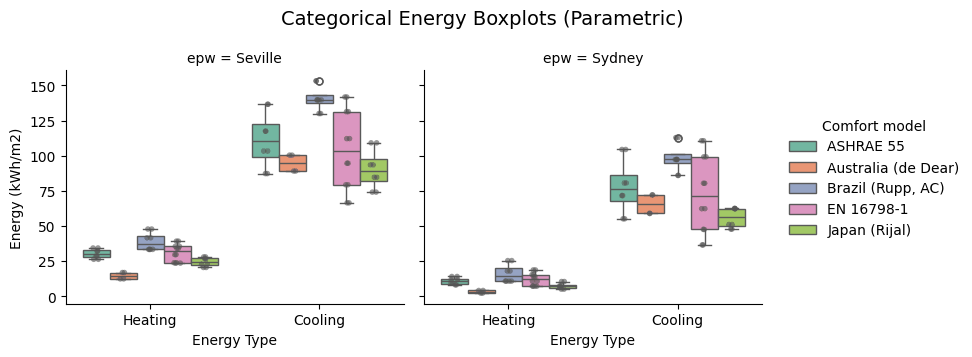

In [15]:
fig_boxplots = parametric.plot_categorical_boxplots(
    df_source="parametric",
    y_vars=[heating_energy_col, cooling_energy_col],
    col="epw",
    hue="Comfort model",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
    show_points=True,
    sharey=True,
    height=3.6,
    aspect=1.1,
)
show_plot_output(fig_boxplots)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF2 predefined parametric: compare heating and cooling electricity

This scatter plot, as in Example 1 of the paper, draws the heating against the cooling electricity of every configuration, one panel per weather file. The colour is the comfort model and the marker the operation mode, so the trade-off between heating and cooling of each alternative becomes visible.

Key arguments used in this cell and why they matter:
- `x`, `y`: heating and cooling electricity.
- `hue`: comfort model.
- `style`: operation mode (`HVACmode`).
- `col`: one panel per weather file.
- `out_dir`, `normalize_per_m2`: output folder and normalization (already done).

Variables created in this cell:
- `fig_scatter`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.

  Parametric scatter plot saved: wf2_parametric_predefined_results\plots\plot_parametric_scatter_parametric_Heating_Electricity_kWh_m2_vs_Cooling_Electricity_kWh_m2.png


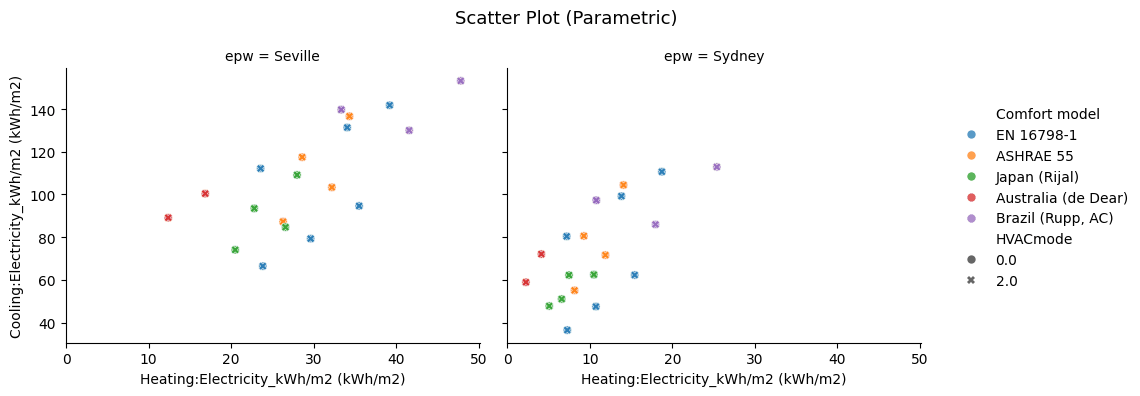

In [16]:
fig_scatter = parametric.plot_parametric_scatter(
    x=heating_energy_col,
    y=cooling_energy_col,
    df_source="parametric",
    hue="Comfort model",
    style="HVACmode",
    col="epw",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
)
show_plot_output(fig_scatter)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF2 predefined parametric: compare HVAC electricity and operative temperature

The second scatter plot of Example 1 relates the annual HVAC electricity to the annual mean operative temperature: configurations that save energy usually do so by letting the indoor temperature drift further from the neutral value.

Key arguments used in this cell and why they matter:
- `x`, `y`: annual HVAC electricity and annual mean operative temperature.
- `hue`, `style`, `col`: comfort model, operation mode and weather file.

Variables created in this cell:
- `fig_scatter_temperature`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.

  Parametric scatter plot saved: wf2_parametric_predefined_results\plots\plot_parametric_scatter_parametric_Electricity_HVAC_kWh_m2_vs_Annual_mean_operative_temperature.png


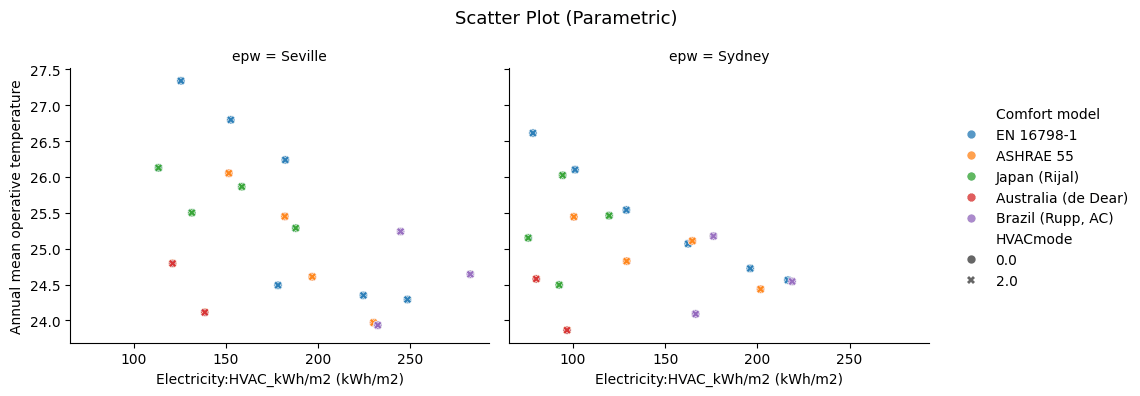

In [17]:
fig_scatter_temperature = parametric.plot_parametric_scatter(
    x=main_energy_col,
    y=temperature_col,
    df_source="parametric",
    hue="Comfort model",
    style="HVACmode",
    col="epw",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
)
show_plot_output(fig_scatter_temperature)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF2 predefined parametric: compare the climates with paired configurations

Every configuration was simulated with both weather files, so the effect of the climate can be read configuration by configuration. The table gives the annual HVAC electricity of each configuration in each climate and the difference between them, sorted by that difference.

Variables created in this cell:
- `configuration_cols`: columns that identify a configuration.
- `paired`: HVAC electricity by configuration (rows) and climate (columns).

What to verify right after running this cell:
- Look for the configurations whose HVAC electricity changes most between climates.

In [18]:
configuration_cols = ["Comfort model", "CAT", "ComfMod", "HVACmode"]
paired = results.pivot_table(index=configuration_cols, columns="epw", values=main_energy_col)[cities]
difference_label = f"{cities[1]} - {cities[0]}"
paired[difference_label] = paired[cities[1]] - paired[cities[0]]
print(paired[difference_label].describe().round(1))
paired.sort_values(difference_label).round(1)


count    40.0
mean     47.4
std      15.4
min      15.8
25%      36.2
50%      49.2
75%      63.8
max      68.5
Name: Seville - Sydney, dtype: float64


epw                                        Sydney  Seville  Seville - Sydney
Comfort model       CAT  ComfMod HVACmode                                   
EN 16798-1          3.0  0.0     2.0        162.4    178.2              15.8
                                 0.0        162.4    178.2              15.8
ASHRAE 55           90.0 0.0     0.0        201.8    230.1              28.3
                                 2.0        201.8    230.1              28.3
EN 16798-1          2.0  0.0     0.0        196.1    224.5              28.4
                                 2.0        196.1    224.5              28.4
                    1.0  0.0     0.0        216.6    248.4              31.9
                                 2.0        216.6    248.4              31.9
ASHRAE 55           80.0 0.0     2.0        164.7    196.8              32.1
                                 0.0        164.7    196.8              32.1
Japan (Rijal)       80.0 3.0     2.0         75.7    113.4              37.6
                                 0.0         75.7    113.4              37.6
                    90.0 3.0     2.0         92.5    131.5              39.0
                                 0.0         92.5    131.5              39.0
Australia (de Dear) 80.0 3.0     2.0         80.1    121.1              41.0
                                 0.0         80.1    121.1              41.0
                    90.0 3.0     2.0         96.8    138.5              41.7
                                 0.0         96.8    138.5              41.7
EN 16798-1          3.0  3.0     0.0         78.3    125.5              47.3
                                 2.0         78.3    125.6              47.3
ASHRAE 55           80.0 3.0     0.0        100.5    151.6              51.1
                                 2.0        100.5    151.6              51.1
EN 16798-1          2.0  3.0     0.0        101.2    152.6              51.4
                                 2.0        101.1    152.6              51.5
ASHRAE 55           90.0 3.0     0.0        129.1    181.9              52.8
                                 2.0        129.1    181.9              52.8
EN 16798-1          1.0  3.0     2.0        128.9    182.2              53.2
                                 0.0        128.9    182.2              53.2
Brazil (Rupp, AC)   90.0 3.0     0.0        218.9    282.5              63.7
                                 2.0        218.9    282.5              63.7
Japan (Rijal)       80.0 0.0     2.0         94.4    158.6              64.2
                                 0.0         94.4    158.6              64.2
Brazil (Rupp, AC)   80.0 0.0     0.0        166.5    232.3              65.8
                                 2.0        166.5    232.3              65.8
                    90.0 0.0     0.0        166.5    232.3              65.8
                                 2.0        166.5    232.3              65.8
Japan (Rijal)       90.0 0.0     2.0        119.6    187.8              68.2
                                 0.0        119.6    187.8              68.2
Brazil (Rupp, AC)   80.0 3.0     0.0        176.2    244.7              68.5
                                 2.0        176.2    244.7              68.5

### Reading the result

Positive differences mean more HVAC electricity in the second climate. Because the configurations are the same in both columns, the differences only come from the climate.

## WF2 predefined parametric: generate parametric heatmap views

Here we generate a heatmap of the HVAC electricity over the comfort models and their categories, for adaptive setpoints in air-conditioned operation (`data_filter`). Without the filter, each cell would average the four combinations of setpoint type and operation mode.

Key arguments used in this cell and why they matter:
- `x`, `y`, `z`: comfort model, category and HVAC electricity.
- `col`: one panel per weather file.
- `data_filter`: keeps `ComfMod` 3 and `HVACmode` 0.
- `out_dir`, `normalize_per_m2`: output folder and normalization (already done).

Variables created in this cell:
- `fig_heatmap`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.

  Parametric heatmap saved: wf2_parametric_predefined_results\plots\plot_parametric_heatmap_parametric_Electricity_HVAC_kWh_m2_by_ComfStand_CAT.png


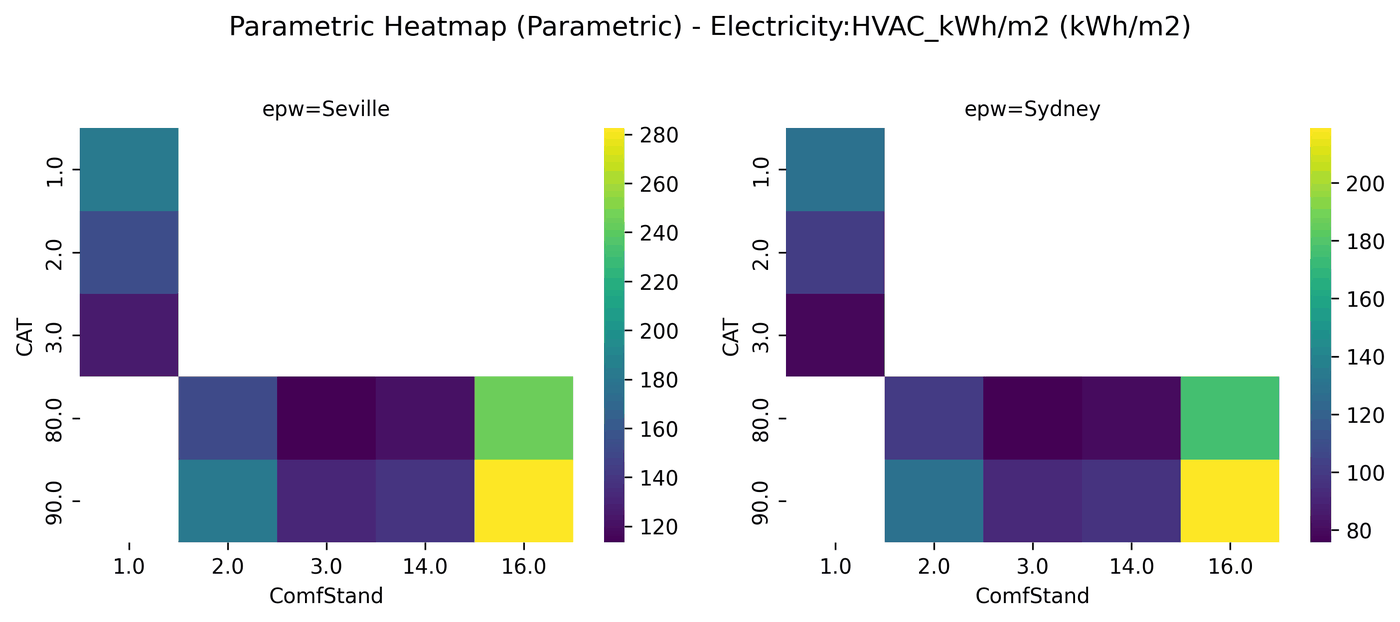

In [19]:
fig_heatmap = parametric.plot_parametric_heatmap(
    x="ComfStand",
    y="CAT",
    z=main_energy_col,
    df_source="parametric",
    col="epw",
    data_filter={"include": {"ComfMod": 3, "HVACmode": 0}},
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
)
show_plot_output(fig_heatmap)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF2 predefined parametric: generate distribution plots of the HVAC electricity

This cell draws the distribution of the annual HVAC electricity of each comfort model, coloured by weather file.

Key arguments used in this cell and why they matter:
- `x`: comfort model.
- `y_vars`: outputs drawn.
- `kind`: `"violin"`.
- `hue`: weather file.
- `show_points`: whether individual points are overlaid on summary plots.

Variables created in this cell:
- `fig_distributions`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.

site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)


  Parametric violin plot saved: wf2_parametric_predefined_results\plots\plot_parametric_violin_parametric_Electricity_HVAC_kWh_m2_by_Comfort_model.png


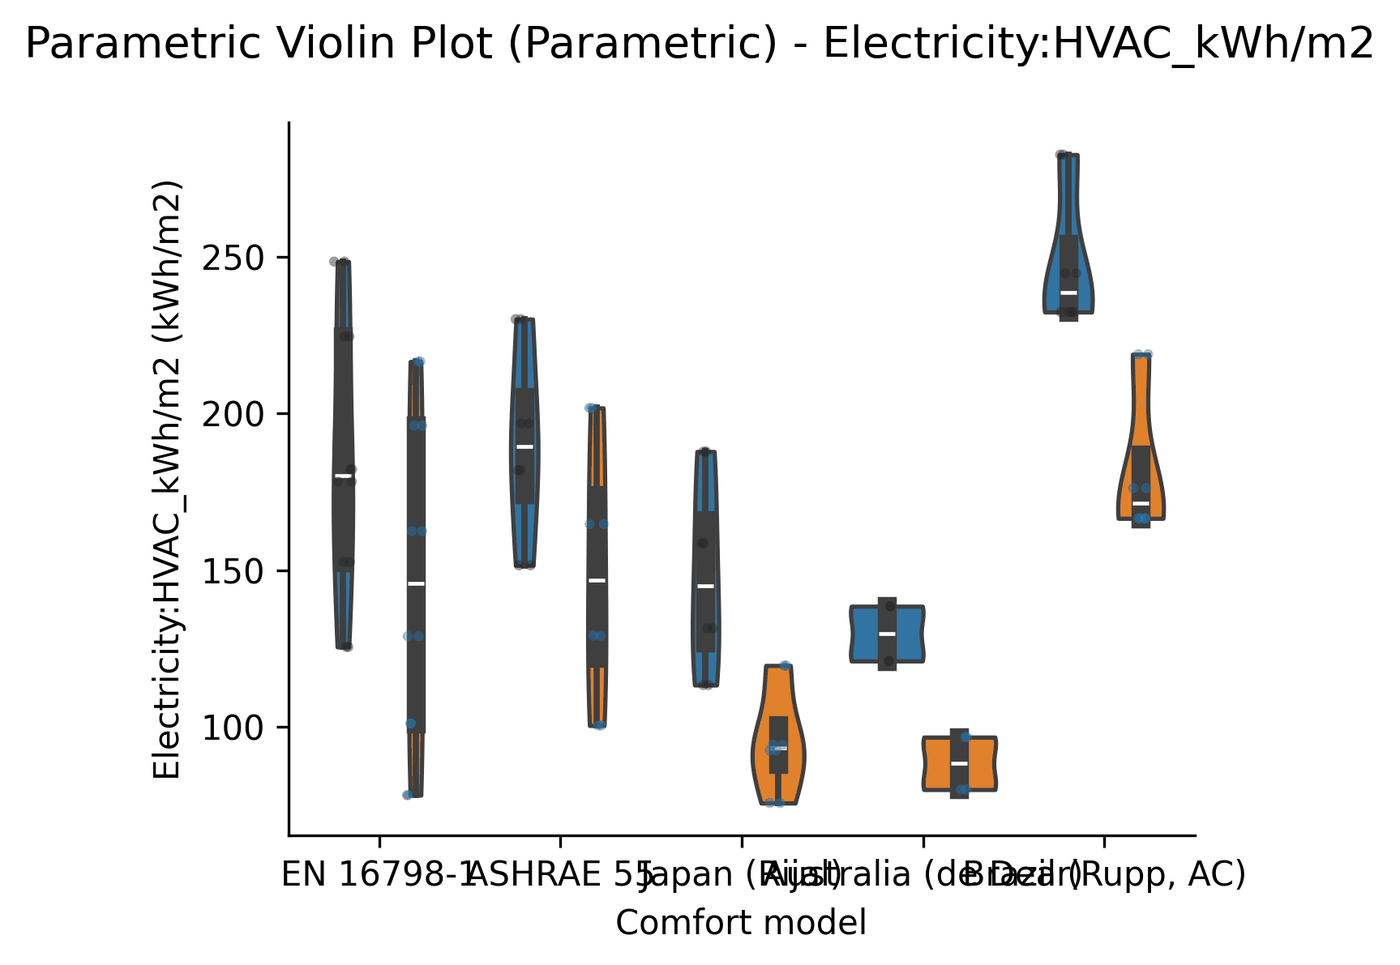

In [20]:
fig_distributions = parametric.plot_parametric_distributions(
    x="Comfort model",
    y_vars=[main_energy_col],
    kind="violin",
    df_source="parametric",
    hue="epw",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
    show_points=True,
)
show_plot_output(fig_distributions)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF2 predefined parametric: generate ECDF views for distribution comparison

This block adds the cumulative distribution of the HVAC electricity of all configurations in each climate.

ECDF curves are especially useful when comparing the full distribution rather than only mean or median behavior.

Key arguments used in this cell and why they matter:
- `x`: output drawn.
- `hue`: weather file.

Variables created in this cell:
- `fig_ecdf`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.

  Parametric ECDF plot saved: wf2_parametric_predefined_results\plots\plot_parametric_ecdf_parametric_Electricity_HVAC_kWh_m2.png


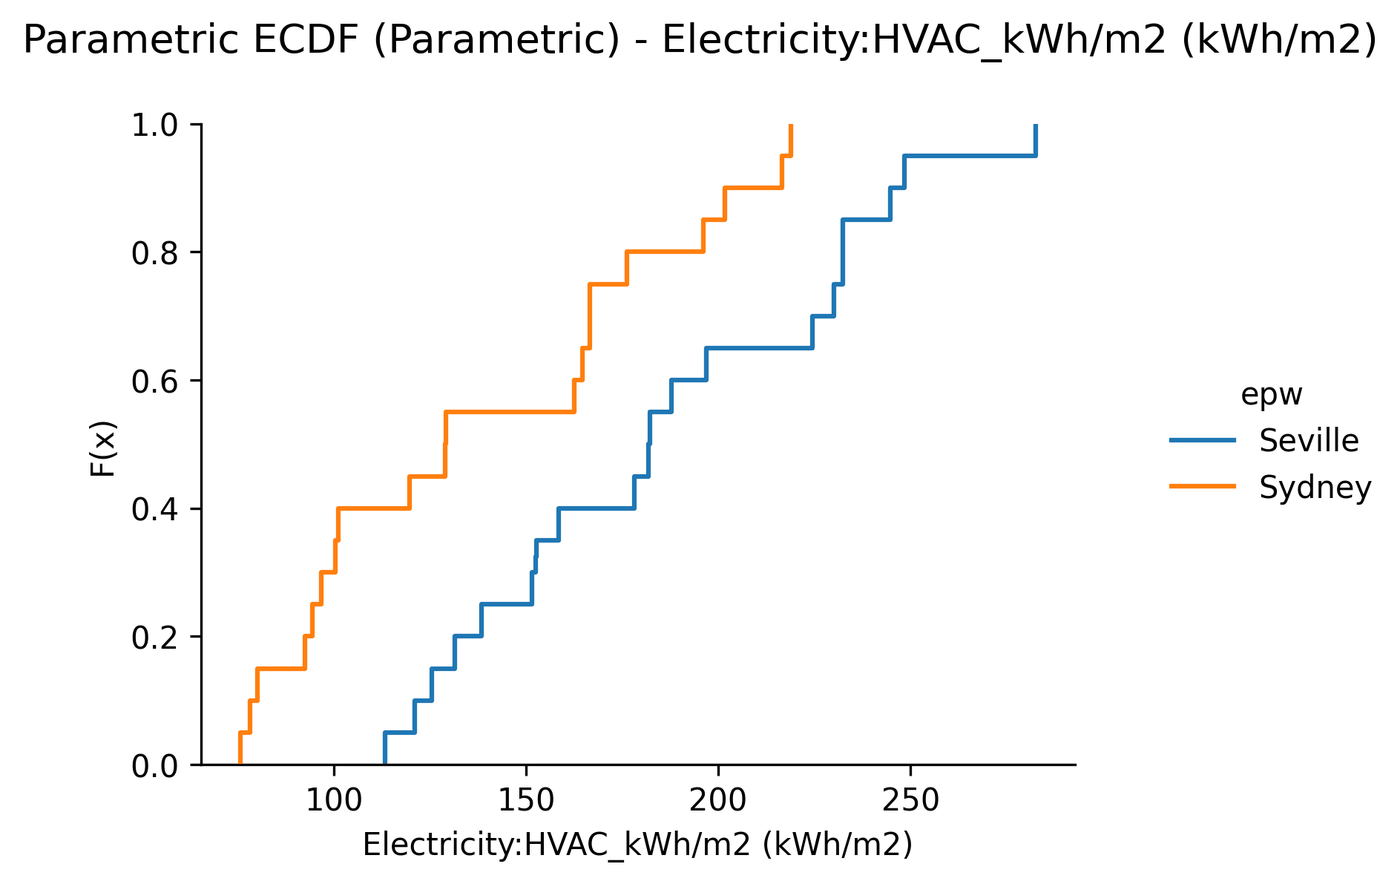

In [21]:
fig_ecdf = parametric.plot_parametric_ecdf(
    x=main_energy_col,
    df_source="parametric",
    hue="epw",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
)
show_plot_output(fig_ecdf)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF2 predefined parametric: simulate the chosen configurations again with hourly outputs

The hourly views need the hourly files, which the main run did not keep. Instead of keeping them for all the configurations, the chosen ones are simulated again, keeping their hourly CSV files: the EN 16798-1 category III configurations, with static or adaptive setpoints, in air-conditioned or mixed-mode operation (four configurations, as in the hourly figure of Example 1 of the paper), in both climates.

The model and the outputs are the same as in the main run, so the annual results of these simulations are the same as before; the cell checks it for the HVAC electricity. The annual results of the main run are kept in `annual_results` and saved to a CSV file, because the new run replaces the results table of `parametric`.

Key arguments used in this cell and why they matter:
- `df`: the rows of the plan with `ComfStand` 1 and `CAT` 3.
- `out_dir`: a subfolder of the results folder.
- `keep_dirs`, `sim_files_extensions` and `sim_files_policy`: keep only the CSV and ERR files of each simulation; the loop after the run deletes `eplusmtr.csv`, a CSV file with the same meters that EnergyPlus writes alongside `eplusout.csv`.

Variables created in this cell:
- `annual_results`: reused in subsequent workflow blocks.
- `hourly_plan`: reused in subsequent workflow blocks.
- `hourly_dir`: reused in subsequent workflow blocks.
- `hourly_outputs`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that 4 configurations x EPWs were simulated and that the largest difference in HVAC electricity is close to 0.

In [22]:
annual_results = parametric.outputs_param_simulation.copy()
annual_results.to_csv(Path(RESULTS_DIRNAME) / "annual_results_kWh_m2.csv", index=False)

hourly_plan = plan_df[(plan_df["ComfStand"] == 1) & (plan_df["CAT"] == 3)].reset_index(drop=True)
print("Configurations simulated again with hourly outputs:", len(hourly_plan))

hourly_dir = Path(RESULTS_DIRNAME) / "hourly"
hourly_outputs = parametric.run_parametric_simulation(
    out_dir=str(hourly_dir),
    df=hourly_plan,
    processes=PROCESSES,
    keep_input=True,
    keep_dirs=True,
    sim_files_extensions=[".csv", ".err"],
    sim_files_policy="keep",
)
for meter_csv in hourly_dir.rglob("eplusmtr.csv"):
    meter_csv.unlink()

key_cols = list(predefined_parameters) + ["epw"]
floor_area = parametric.building_floor_area
floor_area = list(floor_area.values())[0] if isinstance(floor_area, dict) else floor_area
rerun_hvac = hourly_outputs.set_index(key_cols)["Electricity:HVAC"] / 3.6e6 / floor_area
annual_hvac = annual_results.set_index(key_cols)[main_energy_col].reindex(rerun_hvac.index)
print(f"Largest difference in HVAC electricity: {(rerun_hvac - annual_hvac).abs().max():.4f} kWh/m2")

hourly_mb = sum(p.stat().st_size for p in hourly_dir.rglob("*") if p.is_file()) / 1e6
print(f"Hourly results folder: {hourly_mb:.1f} MB")


Configurations simulated again with hourly outputs: 8


  [info] simulation_summary updated for parametric after run_parametric_simulation.
Largest difference in HVAC electricity: 0.0000 kWh/m2
Hourly results folder: 11.0 MB


### Reading the result

The hourly run reproduces the annual results of the same configurations, so the hourly views below describe the same simulations as the annual plots.

## WF2 predefined parametric: build the hourly dataframe of the chosen configurations

This block reads the hourly CSV files of the new run into one long dataframe, with one block of 8,760 rows per simulation and the parameters of each one, and defines the labels of the four cases.

Key arguments used in this cell and why they matter:
- `output_columns`: hourly columns read from the CSV files (names or substrings).
- `skip_confirmation`: skips interactive confirmation prompts.

Variables created in this cell:
- `hourly_df`: the long hourly dataframe (`parametric.outputs_param_simulation_hourly`).
- `case_labels`: labels of the combinations of `ComfMod` and `HVACmode`.
- `case_order`: order of the cases in the plots.

What to verify right after running this cell:
- Confirm that the dataframe has 8,760 rows per simulation.

In [23]:
parametric.get_hourly_df_parametric(
    output_columns=[
        "Zone Operative Temperature",
        "Electricity:HVAC",
        "Site Outdoor Air Drybulb Temperature",
        "CEN 15251 Adaptive Model Running Average",
        "Setpoint Temperature_No Tolerance",
    ],
    skip_confirmation=True,
)
hourly_df = parametric.outputs_param_simulation_hourly
case_labels = {(0, 0): "Static, AC", (3, 0): "Adaptive, AC", (0, 2): "Static, MM", (3, 2): "Adaptive, MM"}
case_order = list(case_labels.values())
print("Hourly shape:", hourly_df.shape)


[get_hourly_df_parametric] Expanding...
  Simulations selected : 8
  Hourly steps per sim : 8760
  Hourly output columns: 7  -> ['FLOOR_1_ZONE:Zone Operative Temperature [C](Hourly)', 'FLOOR_2_ZONE:Zone Operative Temperature [C](Hourly)', 'Electricity:HVAC [J](Hourly)', 'Environment:Site Outdoor Air Drybulb Temperature [C](Hourly)', 'FLOOR_1 RESIDENTIAL LIVING OCCUPANTS:Zone Thermal Comfort CEN 15251 Adaptive Model Running Average Outdoor Air Temperature [C](Hourly)']...
  Source              : csv
  Expanded shape       : ~70,080 rows x 17 cols
  Approx. memory       : ~9.5 MB
Hourly shape: (70080, 17)


## WF2 predefined parametric: monthly distributions of the operative temperature

The monthly distributions (ridgelines) show how the hourly operative temperature of each case is spread in each month, with the two climates overlaid, as in the hourly figure of Example 1 of the paper. No comfort band is drawn (`band=None`): the predefined models have their own bands, so drawing one of them would favour it.

Key arguments used in this cell and why they matter:
- `variable`: hourly variable (name or substring); the zones are averaged.
- `panel`, `panel_labels`, `panel_order`: one panel per case.
- `compare_by`, `compare_order`: the weather files overlaid in each panel.
- `band`: `None`, no comfort band.

Variables created in this cell:
- `fig_monthly`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Compare the spread of the static and adaptive setpoints, and of the air-conditioned and mixed-mode operation.

  plot_monthly_distributions saved: wf2_parametric_predefined_results\plots\plot_monthly_distributions_en16798_cat3.png


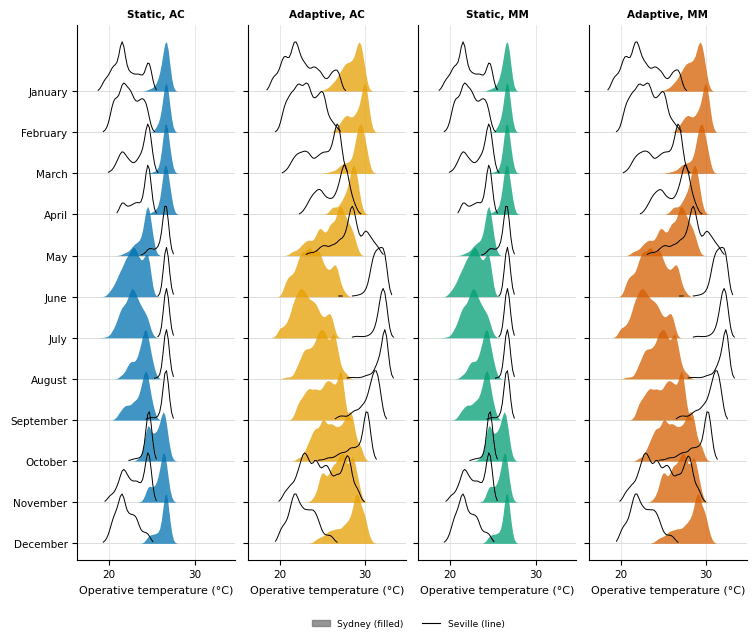

In [24]:
fig_monthly = parametric.plot_monthly_distributions(
    "Zone Operative Temperature",
    panel=["ComfMod", "HVACmode"],
    panel_labels=case_labels,
    panel_order=case_order,
    compare_by="epw",
    compare_order=cities,
    band=None,
    xlabel="Operative temperature (°C)",
    out_dir=str(plot_out_dir),
    filename="plot_monthly_distributions_en16798_cat3.png",
)
show_plot_output(fig_monthly)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF2 predefined parametric: day-by-hour maps

The day-by-hour maps (carpet plots) draw each hour of the year as a cell, with the days on the horizontal axis and the hours of the day on the vertical axis, one row per case and one figure per climate. They show when the operative temperature drifts and when the HVAC system uses electricity.

Key arguments used in this cell and why they matter:
- `variables`: hourly variables drawn (one column of maps per variable).
- `case`, `case_labels`, `case_order`: one row per case.
- `data_filter`: one weather file per figure.

Variables created in this cell:
- `fig_heatmaps`: the figure of the last climate.

What to verify right after running this cell:
- Look for the hours and seasons with the highest HVAC electricity in each case.

  plot_hourly_heatmaps saved: wf2_parametric_predefined_results\plots\plot_hourly_heatmaps_sydney.png


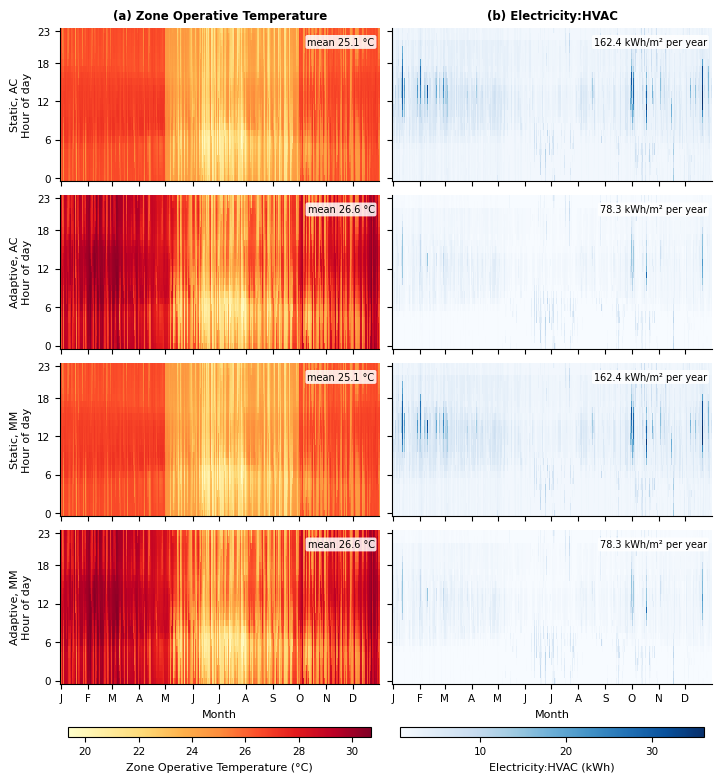

  plot_hourly_heatmaps saved: wf2_parametric_predefined_results\plots\plot_hourly_heatmaps_seville.png


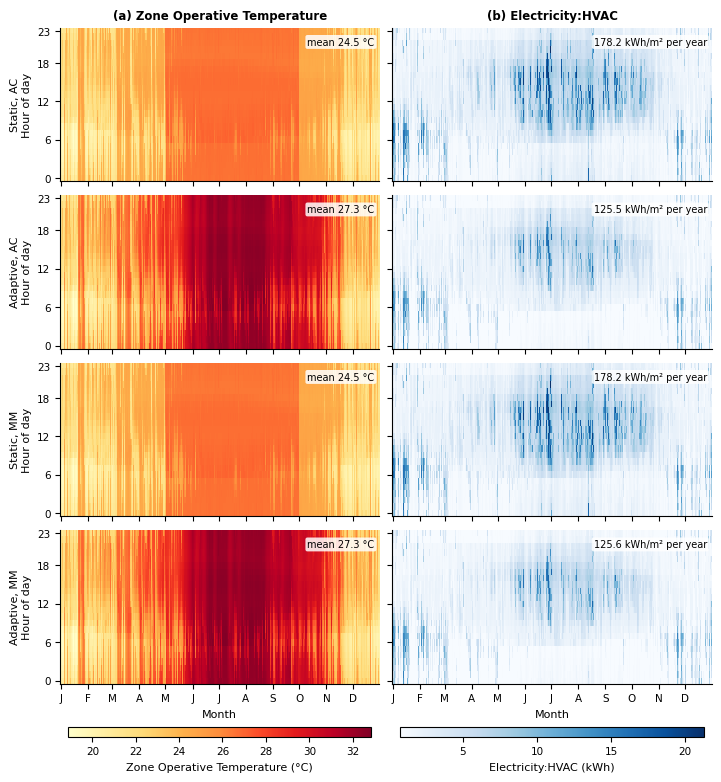

In [25]:
for city in cities:
    fig_heatmaps = parametric.plot_hourly_heatmaps(
        ["Zone Operative Temperature", "Electricity:HVAC"],
        case=["ComfMod", "HVACmode"],
        case_labels=case_labels,
        case_order=case_order,
        data_filter={"include": {"epw": city}},
        out_dir=str(plot_out_dir),
        filename=f"plot_hourly_heatmaps_{city.lower()}.png",
    )
    show_plot_output(fig_heatmaps)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF2 predefined parametric: HVAC electricity against the outdoor temperature

The binned response groups the hours by outdoor air temperature (1 K bins) and draws the mean hourly HVAC electricity of each bin with its interquartile band, an energy signature of each case.

Key arguments used in this cell and why they matter:
- `x`, `y`: outdoor air temperature and HVAC electricity (names or substrings).
- `hue`, `hue_labels`, `hue_order`: one line per case.
- `col`, `col_order`: one panel per weather file.

Variables created in this cell:
- `fig_binned`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Compare the outdoor temperatures at which each case starts heating or cooling.

  plot_hourly_binned_response saved: wf2_parametric_predefined_results\plots\plot_hourly_binned_response.png


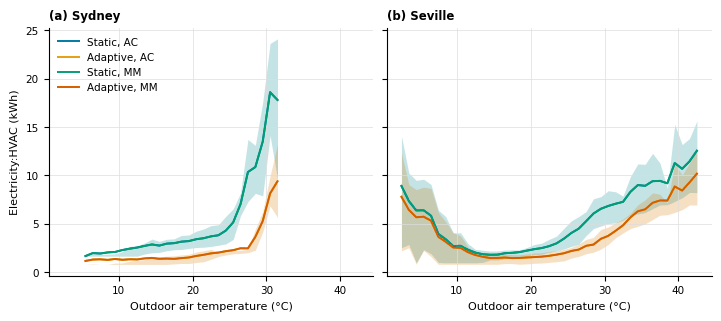

In [26]:
fig_binned = parametric.plot_hourly_binned_response(
    x="Outdoor Air Drybulb Temperature",
    y="Electricity:HVAC",
    hue=["ComfMod", "HVACmode"],
    hue_labels=case_labels,
    hue_order=case_order,
    col="epw",
    col_order=cities,
    xlabel="Outdoor air temperature (°C)",
    out_dir=str(plot_out_dir),
    filename="plot_hourly_binned_response.png",
)
show_plot_output(fig_binned)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF2 predefined parametric: load-duration curves

The load-duration curves sort the hourly HVAC electricity of each simulation from the highest to the lowest value, one panel per case and one line per climate. The left end gives the peak, and the area under the curve the annual electricity.

Key arguments used in this cell and why they matter:
- `variable`: hourly variable (name or substring).
- `panel`, `panel_labels`, `panel_order`: one panel per case.
- `hue`, `hue_order`: one line per weather file.

Variables created in this cell:
- `fig_duration`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Compare the peaks and the hours with HVAC electricity of each case.

  plot_load_duration_curves saved: wf2_parametric_predefined_results\plots\plot_load_duration_curves.png


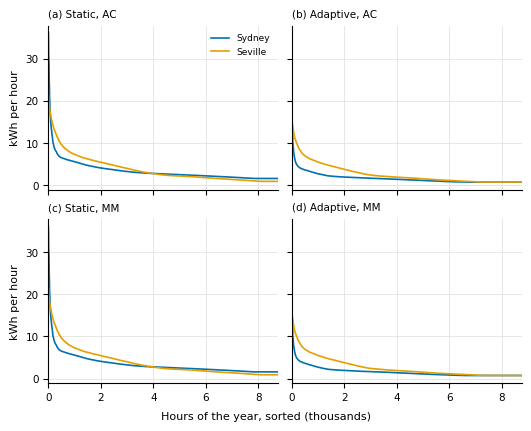

In [27]:
fig_duration = parametric.plot_load_duration_curves(
    "Electricity:HVAC",
    panel=["ComfMod", "HVACmode"],
    panel_labels=case_labels,
    panel_order=case_order,
    hue="epw",
    hue_order=cities,
    out_dir=str(plot_out_dir),
    filename="plot_load_duration_curves.png",
)
show_plot_output(fig_duration)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF2 predefined parametric: hourly scatter matrix

The hourly scatter matrix relates the outdoor air temperature, the operative temperature and the HVAC electricity hour by hour, for the four cases of one climate. The upper panels show the regions with 50 % and 90 % of the hours of each case, and the diagonal their distributions.

Key arguments used in this cell and why they matter:
- `variables`: hourly variables of the matrix.
- `hue`, `hue_labels`, `hue_order`: one colour per case.
- `data_filter`: one weather file.
- `title`: title of the figure.

Variables created in this cell:
- `fig_hourly_matrix`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Compare how the operative temperature follows the outdoor temperature in each case.

  plot_hourly_scatter_matrix saved: wf2_parametric_predefined_results\plots\plot_hourly_scatter_matrix_seville.png


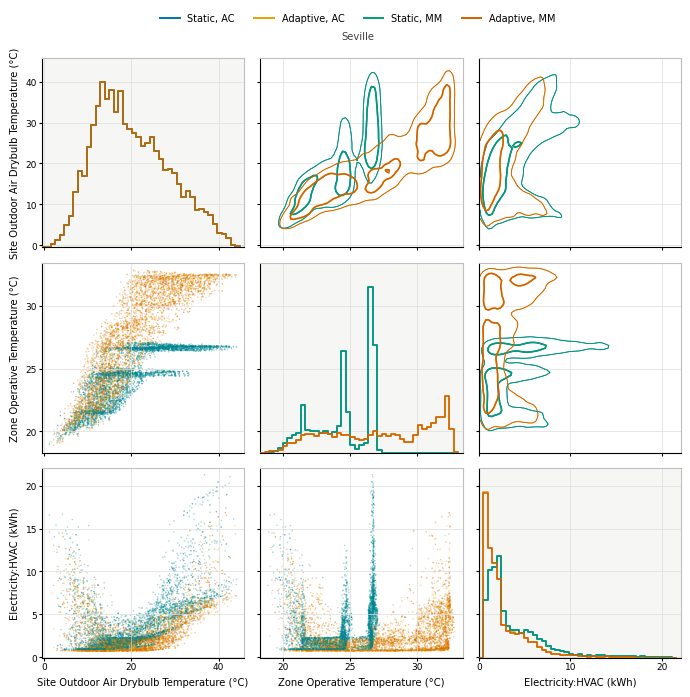

In [28]:
fig_hourly_matrix = parametric.plot_hourly_scatter_matrix(
    ["Outdoor Air Drybulb Temperature", "Zone Operative Temperature", "Electricity:HVAC"],
    hue=["ComfMod", "HVACmode"],
    hue_labels=case_labels,
    hue_order=case_order,
    data_filter={"include": {"epw": cities[-1]}},
    title=cities[-1],
    out_dir=str(plot_out_dir),
    filename=f"plot_hourly_scatter_matrix_{cities[-1].lower()}.png",
)
show_plot_output(fig_hourly_matrix)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF2 predefined parametric: operative temperature and setpoints against the running mean

Finally, the hourly operative temperature of each zone and the adaptive cooling and heating setpoints are drawn against the EN 16798-1 running mean outdoor temperature, one figure per climate, with one row per setpoint type (`ComfMod`) and one column per operation mode (`HVACmode`). The static setpoints are horizontal lines, while the adaptive ones follow the running mean.

Key arguments used in this cell and why they matter:
- `epw_filter`: weather file of the figure.
- `id_vars`: columns kept as identifiers when the variables are stacked; by default, `plot_hourly_scatter` keeps the parameters of the custom model (`CustAST_m`, `CustAST_n`), so `ComfMod`, `HVACmode` and the running mean are listed here.
- `x`: column of the running mean on the x axis.
- `value_tokens`: hourly variables drawn on the y axis (names or substrings).
- `row`, `col`: facets by setpoint type and operation mode.
- `x_label`, `y_label`: axis labels.

Variables created in this cell:
- `running_mean_col`: column of the EN 16798-1 running mean.
- `scatter_grid`: the figure of the last climate.

What to verify right after running this cell:
- Check that the operative temperature stays between the setpoints in air-conditioned operation.

  Hourly scatter plot saved: wf2_parametric_predefined_results\plots\plot_hourly_scatter_rmot_sydney.png


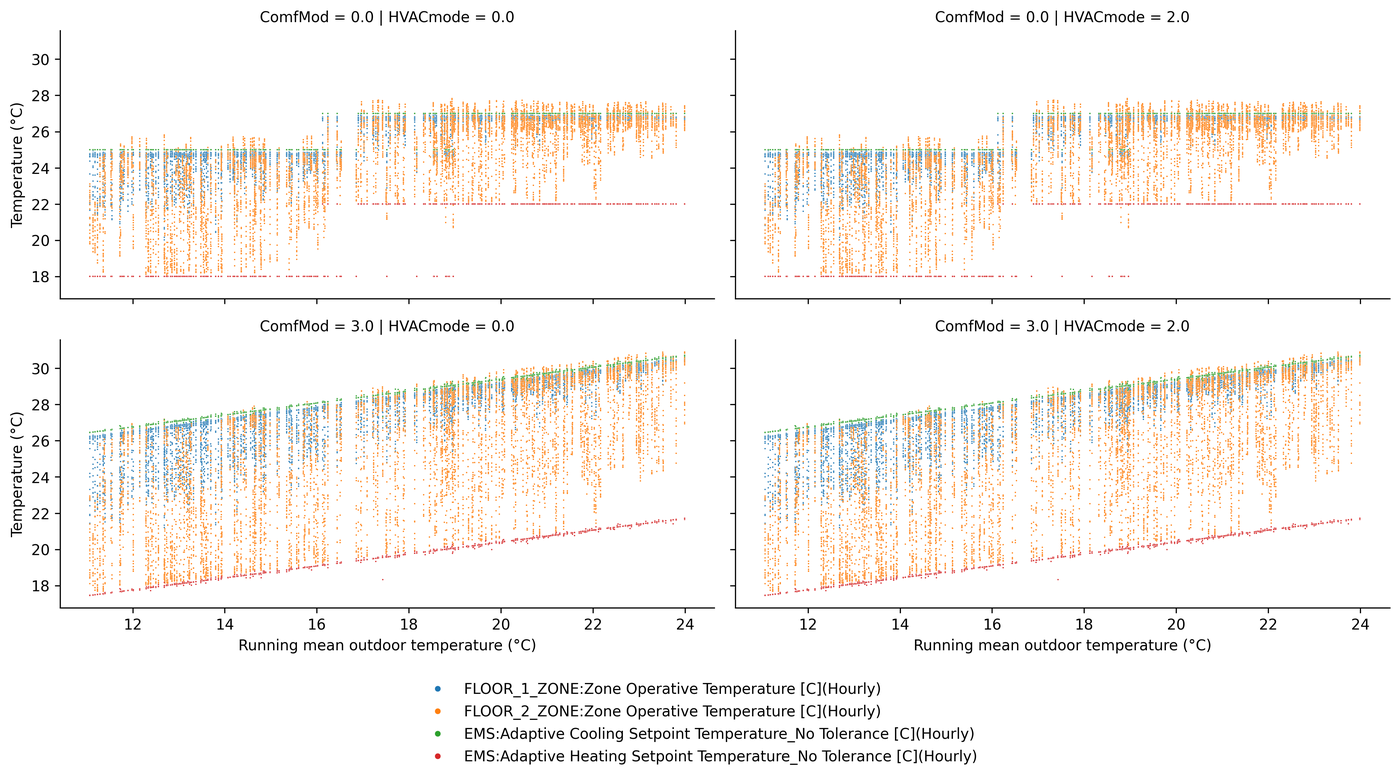

  Hourly scatter plot saved: wf2_parametric_predefined_results\plots\plot_hourly_scatter_rmot_seville.png


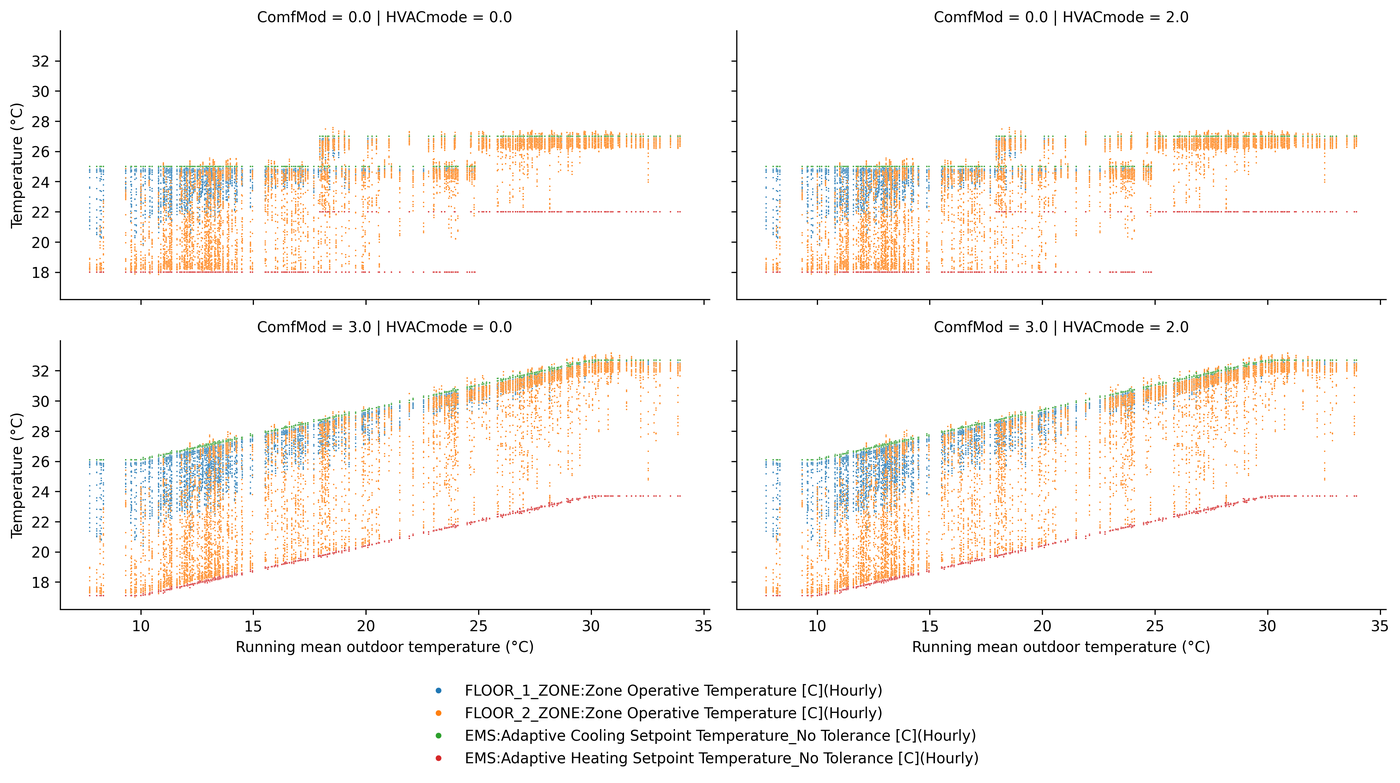

In [29]:
running_mean_col = next(c for c in hourly_df.columns if "CEN 15251 Adaptive Model Running Average" in c)
for city in cities:
    scatter_grid = parametric.plot_hourly_scatter(
        epw_filter=city,
        id_vars=["datetime", "ComfMod", "HVACmode", "epw", running_mean_col],
        x=running_mean_col,
        value_tokens=["Zone Operative Temperature", "Setpoint Temperature_No Tolerance"],
        row="ComfMod",
        col="HVACmode",
        x_label="Running mean outdoor temperature (°C)",
        y_label="Temperature (°C)",
        out_dir=str(plot_out_dir),
        filename=f"plot_hourly_scatter_rmot_{city.lower()}.png",
    )
    show_plot_output(scatter_grid.saved_path)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.